# Lab Session 2 — Principal Component Analysis (PCA)
**National Higher School of Advanced Technologies — Master 1 — Machine Learning (2026/2027)**

**Objective:** implement PCA from scratch with NumPy and compare it with `sklearn.decomposition.PCA`.

## Part A — PCA from scratch

### 1. Load the dataset into a Pandas DataFrame

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

data = {
    "Student": ["S1", "S2", "S3", "S4", "S5", "S6"],
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics":  [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms":  [13, 15, 9, 17, 10, 14],
}
df = pd.DataFrame(data).set_index("Student")
df

,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14


### 2. Dimensions and descriptive statistics

In [2]:
print("Shape (students, subjects):", df.shape)
df.describe()

Shape (students, subjects): (6, 4)


,Mathematics,Statistics,Programming,Algorithms
count,6.0000,6.0000,6.0000,6.0000
mean,12.6667,12.8333,13.6667,13.0000
std,3.3267,2.6394,3.0111,3.0332
min,8.0000,9.0000,10.0000,9.0000
25%,10.5000,11.2500,11.5000,10.7500
50%,13.0000,13.0000,13.5000,13.5000
75%,14.7500,14.7500,15.5000,14.7500
max,17.0000,16.0000,18.0000,17.0000


### 3. Standardize the variables
$$z_{ij}=\frac{x_{ij}-\bar{x}_j}{s_j}$$
We use the sample standard deviation (`ddof=1`, the pandas default), consistent with the covariance in the next step.

In [3]:
X = df.values.astype(float)
mean = X.mean(axis=0)
std = X.std(axis=0, ddof=1)
Z = (X - mean) / std

Z_df = pd.DataFrame(Z, index=df.index, columns=df.columns)
print("Column means of Z (≈ 0):", Z.mean(axis=0))
print("Column std of Z (= 1):  ", Z.std(axis=0, ddof=1))
Z_df

Column means of Z (≈ 0): [ 0. -0.  0.  0.]
Column std of Z (= 1):   [1. 1. 1. 1.]


,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,-0.2004,-0.6946,0.1107,0.0000
S2,0.7014,0.4420,0.7749,0.6594
S3,-1.4028,-1.4523,-1.2177,-1.3188
S4,1.3026,1.1997,1.4391,1.3188
S5,-0.8016,-0.3157,-0.8856,-0.9891
S6,0.4008,0.8209,-0.2214,0.3297


### 4. Covariance matrix of the standardized data
$$C=\frac{1}{n-1}Z^\top Z$$
Since the data are standardized, $C$ is the **correlation matrix** of the original variables.

In [4]:
n = Z.shape[0]
cov_matrix = (Z.T @ Z) / (n - 1)
print("Check with np.cov:", np.allclose(cov_matrix, np.cov(Z, rowvar=False)))
pd.DataFrame(cov_matrix, index=df.columns, columns=df.columns)

Check with np.cov: True


,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.0000,0.9263,0.9451,0.9911
Statistics,0.9263,1.0000,0.7717,0.8744
Programming,0.9451,0.7717,1.0000,0.9635
Algorithms,0.9911,0.8744,0.9635,1.0000


### 5. Eigenvalues and eigenvectors (NumPy)

In [5]:
# eigh is the right choice for a symmetric matrix (real eigenvalues, orthonormal eigenvectors)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
print("Eigenvalues (unsorted):", eigenvalues)
print("Eigenvectors (columns):\n", eigenvectors)

Eigenvalues (unsorted): [0.0009 0.0191 0.2402 3.7397]
Eigenvectors (columns):
 [[ 0.8296  0.2093  0.032  -0.5167]
 [-0.2478 -0.3149  0.7822 -0.477 ]
 [-0.1264 -0.6249 -0.5922 -0.4928]
 [-0.4841  0.683  -0.1909 -0.5125]]


### 6. Sort eigenvalues in descending order and reorder eigenvectors

In [6]:
idx = np.argsort(eigenvalues)[::-1]
eigenvalues_sorted = eigenvalues[idx]
eigenvectors_sorted = eigenvectors[:, idx]

print("Sorted eigenvalues:", eigenvalues_sorted)
pd.DataFrame(eigenvectors_sorted, index=df.columns,
             columns=[f"PC{i+1}" for i in range(len(idx))])

Sorted eigenvalues: [3.7397 0.2402 0.0191 0.0009]


,PC1,PC2,PC3,PC4
Mathematics,-0.5167,0.0320,0.2093,0.8296
Statistics,-0.4770,0.7822,-0.3149,-0.2478
Programming,-0.4928,-0.5922,-0.6249,-0.1264
Algorithms,-0.5125,-0.1909,0.6830,-0.4841


### 7. Select the two eigenvectors with the largest eigenvalues

In [7]:
k = 2
W = eigenvectors_sorted[:, :k]
pd.DataFrame(W, index=df.columns, columns=["PC1", "PC2"])

,PC1,PC2
Mathematics,-0.5167,0.0320
Statistics,-0.4770,0.7822
Programming,-0.4928,-0.5922
Algorithms,-0.5125,-0.1909


### 8. Project the standardized data onto the two principal components
$$Y = Z\,W$$

In [8]:
Y_scratch = Z @ W
Y_scratch_df = pd.DataFrame(Y_scratch, index=df.index, columns=["PC1", "PC2"])
Y_scratch_df

,PC1,PC2
Student,,
S1,0.3803,-0.6153
S2,-1.2930,-0.2166
S3,2.6935,-0.2080
S4,-2.6304,-0.1239
S5,1.5081,0.4407
S6,-0.6585,0.7231


### 9. Explained variance ratio and cumulative explained variance

In [9]:
evr_scratch = eigenvalues_sorted / eigenvalues_sorted.sum()
cum_evr_scratch = np.cumsum(evr_scratch)

pd.DataFrame({
    "Eigenvalue": eigenvalues_sorted,
    "Explained variance ratio": evr_scratch,
    "Cumulative": cum_evr_scratch,
}, index=[f"PC{i+1}" for i in range(len(evr_scratch))])

,Eigenvalue,Explained variance ratio,Cumulative
PC1,3.7397,0.9349,0.9349
PC2,0.2402,0.0601,0.9950
PC3,0.0191,0.0048,0.9998
PC4,0.0009,0.0002,1.0000


## Part B — PCA with Scikit-learn

### 10–11. Apply `PCA` and reduce to two components
Scikit-learn's `PCA` only **centers** the data (it does not scale), so we give it the already standardized matrix `Z` to make the comparison fair.

In [10]:
pca = PCA(n_components=2)
Y_sklearn = pca.fit_transform(Z)

### 12. Transformed coordinates

In [11]:
Y_sklearn_df = pd.DataFrame(Y_sklearn, index=df.index, columns=["PC1", "PC2"])
Y_sklearn_df

,PC1,PC2
Student,,
S1,-0.3803,-0.6153
S2,1.2930,-0.2166
S3,-2.6935,-0.2080
S4,2.6304,-0.1239
S5,-1.5081,0.4407
S6,0.6585,0.7231


### 13. Explained variance ratio and cumulative explained variance

In [12]:
evr_sklearn = pca.explained_variance_ratio_
cum_evr_sklearn = np.cumsum(evr_sklearn)

pd.DataFrame({
    "Eigenvalue (explained_variance_)": pca.explained_variance_,
    "Explained variance ratio": evr_sklearn,
    "Cumulative": cum_evr_sklearn,
}, index=["PC1", "PC2"])

,Eigenvalue (explained_variance_),Explained variance ratio,Cumulative
PC1,3.7397,0.9349,0.9349
PC2,0.2402,0.0601,0.9950


## Part C — Comparison and interpretation

### 14. Compare the principal component coordinates

In [13]:
comparison = pd.concat(
    {"Scratch": Y_scratch_df, "Sklearn": Y_sklearn_df,
     "Difference": Y_scratch_df - Y_sklearn_df}, axis=1)
display(comparison)

print("Identical coordinates?        ", np.allclose(Y_scratch, Y_sklearn))
print("Identical up to sign per PC?  ", np.allclose(np.abs(Y_scratch), np.abs(Y_sklearn)))

# Sign of each component in the two implementations
signs = np.sign((Y_scratch * Y_sklearn).sum(axis=0))
print("Relative sign of each PC (scratch vs sklearn):", signs)

Scratch         Sklearn         Difference            
            PC1     PC2     PC1     PC2        PC1         PC2
Student                                                       
S1       0.3803 -0.6153 -0.3803 -0.6153     0.7607 -4.4409e-16
S2      -1.2930 -0.2166  1.2930 -0.2166    -2.5861 -1.6653e-16
S3       2.6935 -0.2080 -2.6935 -0.2080     5.3871 -4.9960e-16
S4      -2.6304 -0.1239  2.6304 -0.1239    -5.2608 -3.1919e-16
S5       1.5081  0.4407 -1.5081  0.4407     3.0162 -6.1062e-16
S6      -0.6585  0.7231  0.6585  0.7231    -1.3170 -3.3307e-16

Identical coordinates?         False
Identical up to sign per PC?   True
Relative sign of each PC (scratch vs sklearn): [-1.  1.]


### 15. Compare eigenvalues and explained variance ratios

In [14]:
comp2 = pd.DataFrame({
    "Eigenvalue scratch": eigenvalues_sorted[:2],
    "Eigenvalue sklearn": pca.explained_variance_,
    "EVR scratch": evr_scratch[:2],
    "EVR sklearn": evr_sklearn,
    "Cum. EVR scratch": cum_evr_scratch[:2],
    "Cum. EVR sklearn": cum_evr_sklearn,
}, index=["PC1", "PC2"])
display(comp2)
print("Eigenvalues match: ", np.allclose(eigenvalues_sorted[:2], pca.explained_variance_))
print("EVR match:         ", np.allclose(evr_scratch[:2], evr_sklearn))

,Eigenvalue scratch,Eigenvalue sklearn,EVR scratch,EVR sklearn,Cum. EVR scratch,Cum. EVR sklearn
PC1,3.7397,3.7397,0.9349,0.9349,0.9349,0.9349
PC2,0.2402,0.2402,0.0601,0.0601,0.9950,0.9950


Eigenvalues match:  True
EVR match:          True


### 16. Plot the students in two dimensions (both implementations)

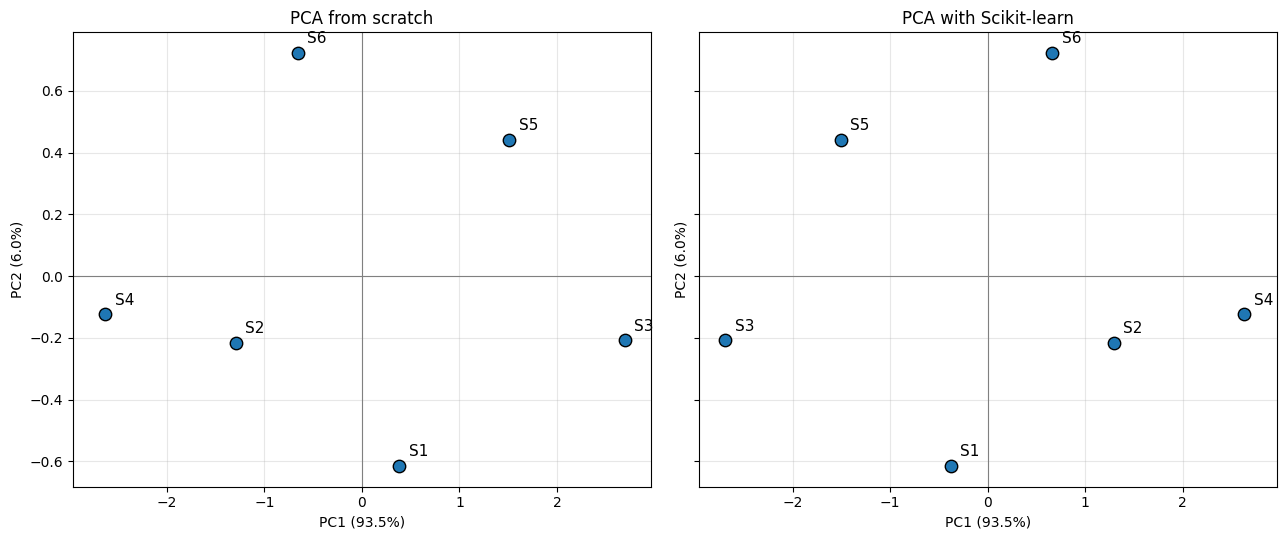

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)

for ax, Y, title in zip(axes, [Y_scratch, Y_sklearn],
                        ["PCA from scratch", "PCA with Scikit-learn"]):
    ax.scatter(Y[:, 0], Y[:, 1], s=80, color="tab:blue", edgecolor="k", zorder=3)
    for name, (x, y) in zip(df.index, Y):
        ax.annotate(name, (x, y), textcoords="offset points", xytext=(7, 7), fontsize=11)
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({evr_scratch[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({evr_scratch[1]*100:.1f}%)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Extra: overlay after aligning the signs, plus the scree plot and the variable loadings.

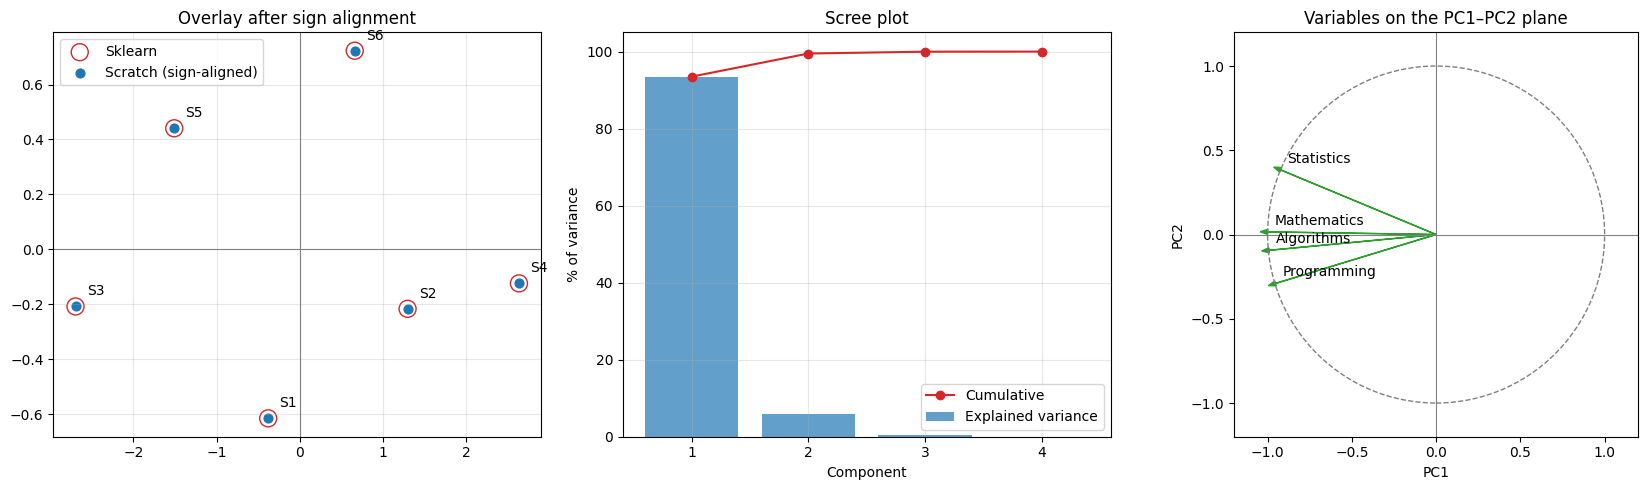

In [16]:
# Align the sign of the scratch components with sklearn's
Y_aligned = Y_scratch * signs

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Overlay
ax = axes[0]
ax.scatter(Y_sklearn[:, 0], Y_sklearn[:, 1], s=150, facecolors="none",
           edgecolors="tab:red", label="Sklearn")
ax.scatter(Y_aligned[:, 0], Y_aligned[:, 1], s=40, color="tab:blue", label="Scratch (sign-aligned)")
for name, (x, y) in zip(df.index, Y_sklearn):
    ax.annotate(name, (x, y), textcoords="offset points", xytext=(8, 8))
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_title("Overlay after sign alignment"); ax.legend(); ax.grid(alpha=0.3)

# Scree plot
ax = axes[1]
comps = np.arange(1, len(evr_scratch) + 1)
ax.bar(comps, evr_scratch * 100, alpha=0.7, label="Explained variance")
ax.plot(comps, cum_evr_scratch * 100, "o-", color="tab:red", label="Cumulative")
ax.set_xticks(comps); ax.set_xlabel("Component"); ax.set_ylabel("% of variance")
ax.set_title("Scree plot"); ax.legend(); ax.grid(alpha=0.3)

# Loadings (correlation circle style)
ax = axes[2]
loadings = W * np.sqrt(eigenvalues_sorted[:2])   # correlation of variables with PCs
for i, var in enumerate(df.columns):
    ax.arrow(0, 0, loadings[i, 0], loadings[i, 1], head_width=0.03, color="tab:green")
    ax.annotate(var, (loadings[i, 0], loadings[i, 1]), textcoords="offset points", xytext=(5, 5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, ls="--", color="gray"))
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal")
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Variables on the PC1–PC2 plane")
plt.tight_layout(); plt.show()

### 17. Differences between the two implementations — sign changes

In [17]:
print("Scratch eigenvectors (PC1, PC2):\n", W)
print("\nSklearn components_ (transposed):\n", pca.components_.T)
print("\nProduct of the two (±1 on the diagonal means same direction / flipped):\n",
      np.round(W.T @ pca.components_.T, 4))

Scratch eigenvectors (PC1, PC2):
 [[-0.5167  0.032 ]
 [-0.477   0.7822]
 [-0.4928 -0.5922]
 [-0.5125 -0.1909]]

Sklearn components_ (transposed):
 [[ 0.5167  0.032 ]
 [ 0.477   0.7822]
 [ 0.4928 -0.5922]
 [ 0.5125 -0.1909]]

Product of the two (±1 on the diagonal means same direction / flipped):
 [[-1. -0.]
 [-0.  1.]]


**Explanation.** An eigenvector is only defined up to a multiplicative constant: if $v$ is an eigenvector of $C$ associated with $\lambda$, then $-v$ is too, since $C(-v)=\lambda(-v)$. Both $v$ and $-v$ are unit vectors, so neither is "more correct". The sign returned depends on the algorithm:

- `np.linalg.eigh` uses LAPACK's symmetric eigen-solver, whose sign convention is arbitrary.
- Scikit-learn computes the SVD of the centered data and then applies `svd_flip`, which makes the sign deterministic (the largest-magnitude entry in each row of `components_` is forced positive).

Flipping the sign of a component mirrors the points about the opposite axis, so **distances between students, explained variance and the interpretation do not change**. Any other difference is only floating-point noise (~1e-15).

Two minor technical points: (i) sklearn uses the SVD rather than the covariance eigen-decomposition (same result, numerically more stable), and (ii) sklearn centers but does not scale, which is why we fed it the standardized data.

### 18. Total variance retained by the first two components

In [18]:
retained = cum_evr_scratch[1] * 100
print(f"PC1 explains {evr_scratch[0]*100:.2f}% of the variance")
print(f"PC2 explains {evr_scratch[1]*100:.2f}% of the variance")
print(f"PC1 + PC2 retain {retained:.2f}% of the total variance")
print(f"Information lost: {100 - retained:.2f}%")
print(f"(sklearn) PC1 + PC2: {cum_evr_sklearn[1]*100:.2f}%")

PC1 explains 93.49% of the variance
PC2 explains 6.01% of the variance
PC1 + PC2 retain 99.50% of the total variance
Information lost: 0.50%
(sklearn) PC1 + PC2: 99.50%


## Interpretation of the findings

- **Eigenvalues:** 3.7397, 0.2402, 0.0191, 0.0009 (they sum to 4, the number of standardized variables).
- **PC1 (93.49 %)** has loadings of the same sign and almost equal magnitude (≈ 0.48–0.52) on all four subjects. It is therefore a **general performance axis**: it separates strong students (S4, S2) from weak ones (S3, S5) across every subject at once. The grades are highly positively correlated, so the data are almost one-dimensional.
- **PC2 (6.01 %)** is a small contrast mainly between **Statistics** (positive loading) and **Programming** (negative loading). It distinguishes students with a similar overall level but different profiles, e.g. S6 and S5 (relatively stronger in Statistics) versus S1 (relatively stronger in Programming).
- **Comparison:** both implementations give identical eigenvalues, explained variance ratios and coordinates, except that **PC1 has opposite sign** (scratch: all loadings negative; sklearn: all positive). PC2 has the same sign. This is only an arbitrary orientation of the axis, as explained in question 17: the scatter plot is a mirror image along PC1, and relative positions are unchanged.
- **Variance retained:** the first two components keep **99.50 %** of the total variance (only 0.50 % lost), so reducing 4 dimensions to 2 is almost lossless. In fact PC1 alone (93.49 %) is already enough for a ranking of the students.